# Phân loại rác bằng ResNet18
ResNet18 pretrained ImageNet (skip connection), thay lớp `fc` thành 12 lớp và fine-tune toàn bộ mạng.

Dữ liệu: **Garbage Classification** (12 loại rác, ~15.5k ảnh) trong `data/garbage/`.

In [1]:
import torch, torch.nn as nn
from torchvision import models
import common as C
print(C.DEVICE)

cuda


## 1. Dữ liệu

12 lớp: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
{'train': 10864, 'val': 2328, 'test': 2328}


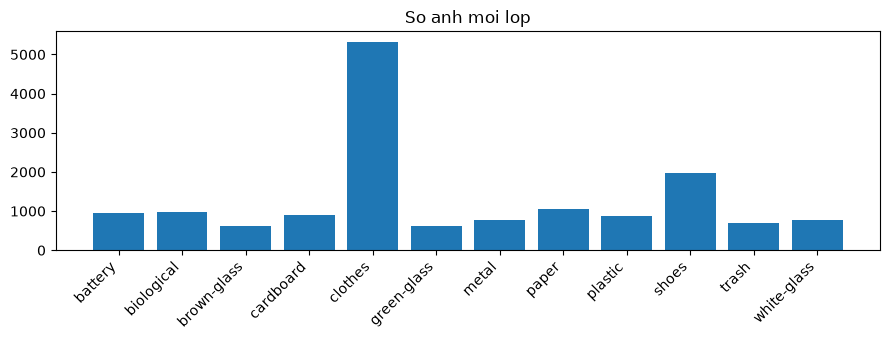

{'battery': 945,
 'biological': 985,
 'brown-glass': 607,
 'cardboard': 891,
 'clothes': 5325,
 'green-glass': 629,
 'metal': 769,
 'paper': 1050,
 'plastic': 865,
 'shoes': 1977,
 'trash': 697,
 'white-glass': 780}

In [2]:
IMG_SIZE, BATCH_SIZE = 128, 64
classes, loaders, y_train = C.get_loaders(IMG_SIZE, BATCH_SIZE)
print(len(classes), 'lớp:', classes)
print({k: len(v.dataset) for k, v in loaders.items()})
C.plot_class_distribution(classes)

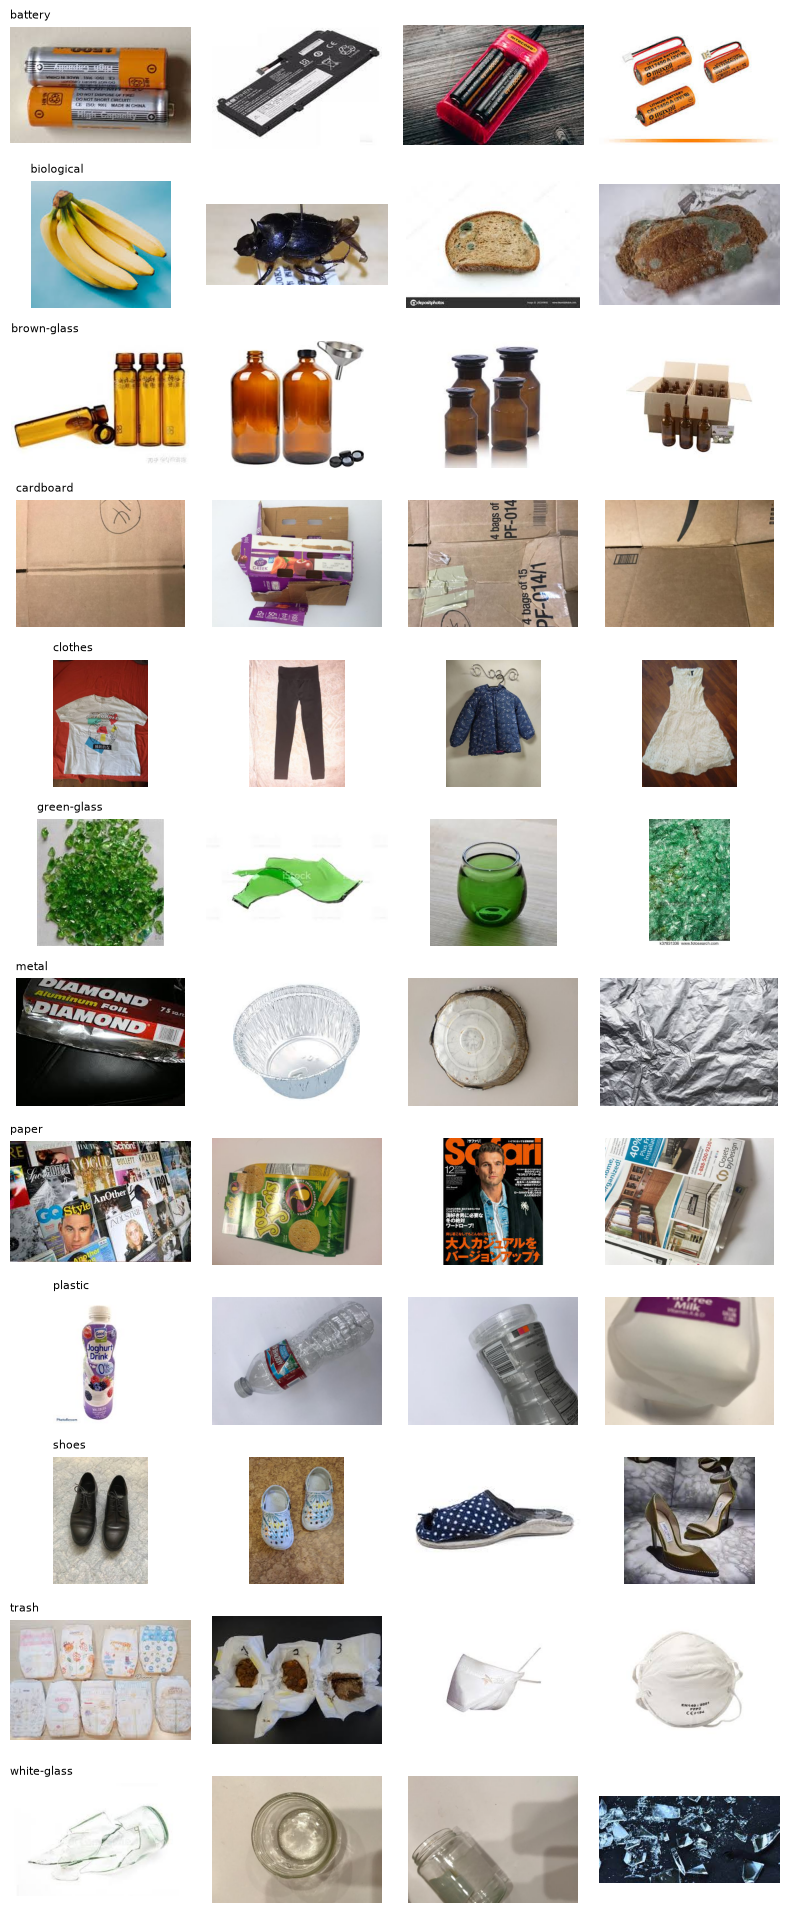

In [3]:
C.show_samples(classes)

## 2. Mô hình

In [4]:
model = models.resnet18(weights="IMAGENET1K_V1")
model.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(model.fc.in_features, len(classes)))

In [5]:
print(f'{sum(p.numel() for p in model.parameters())/1e6:.2f}M tham số')

11.18M tham số


## 3. Huấn luyện
Dùng AdamW + OneCycleLR, mixed precision, loss có trọng số lớp (dữ liệu mất cân bằng: `clothes` nhiều hơn hẳn các lớp khác). Chọn checkpoint theo val accuracy.

In [6]:
EPOCHS, LR = 10, 0.001
model, hist, t = C.train_model('resnet18', model, loaders, y_train, len(classes), EPOCHS, LR)
print(f'Thời gian train: {t/60:.1f} phút')

ep 01/10 | train loss 0.890 acc 0.754 | val loss 0.398 acc 0.901
ep 02/10 | train loss 0.547 acc 0.862 | val loss 0.775 acc 0.751
ep 03/10 | train loss 0.569 acc 0.845 | val loss 0.862 acc 0.758
ep 04/10 | train loss 0.458 acc 0.871 | val loss 0.538 acc 0.865
ep 05/10 | train loss 0.335 acc 0.902 | val loss 0.500 acc 0.872
ep 06/10 | train loss 0.235 acc 0.932 | val loss 0.317 acc 0.916
ep 07/10 | train loss 0.150 acc 0.954 | val loss 0.249 acc 0.948
ep 08/10 | train loss 0.076 acc 0.978 | val loss 0.229 acc 0.942
ep 09/10 | train loss 0.045 acc 0.986 | val loss 0.215 acc 0.950
ep 10/10 | train loss 0.034 acc 0.989 | val loss 0.209 acc 0.952
Thời gian train: 7.8 phút


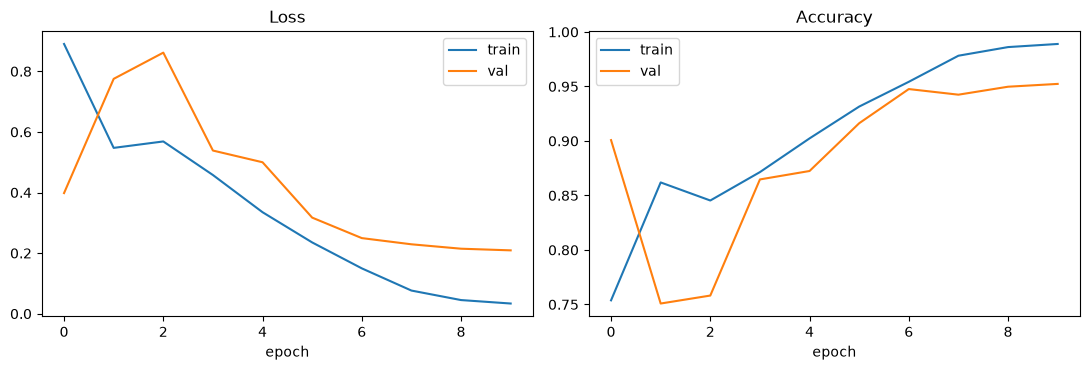

In [7]:
C.plot_history(hist)

## 4. Đánh giá trên tập test

              precision    recall  f1-score   support

     battery     0.9103    0.9296    0.9199       142
  biological     0.9252    0.9252    0.9252       147
 brown-glass     0.9263    0.9670    0.9462        91
   cardboard     0.9677    0.9023    0.9339       133
     clothes     0.9898    0.9725    0.9811       799
 green-glass     0.9474    0.9474    0.9474        95
       metal     0.9009    0.8621    0.8811       116
       paper     0.9068    0.9299    0.9182       157
     plastic     0.8462    0.8462    0.8462       130
       shoes     0.9057    0.9697    0.9366       297
       trash     0.9700    0.9327    0.9510       104
 white-glass     0.8889    0.8889    0.8889       117

    accuracy                         0.9399      2328
   macro avg     0.9238    0.9228    0.9230      2328
weighted avg     0.9407    0.9399    0.9400      2328



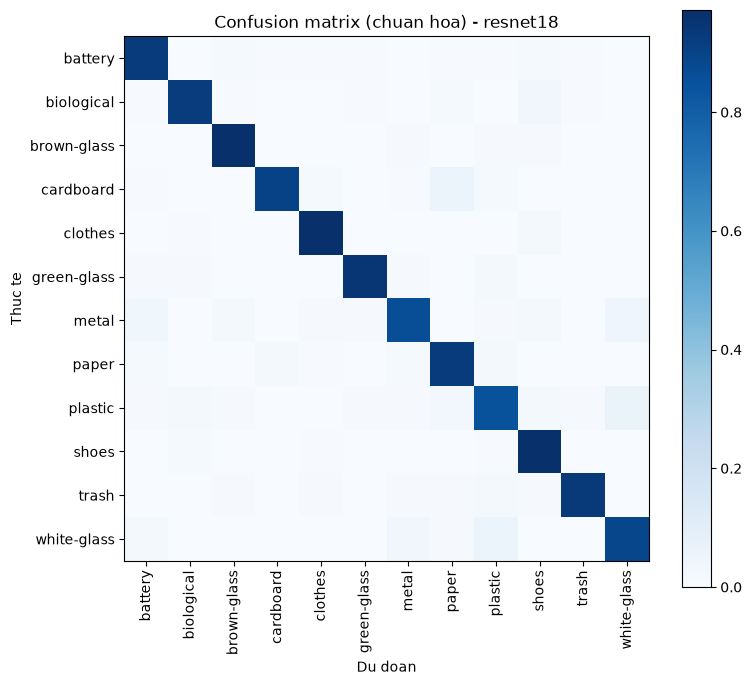

Test accuracy: 0.9399 | macro F1: 0.9230


In [8]:
res = C.evaluate('resnet18', model, loaders['test'], classes, hist, t)

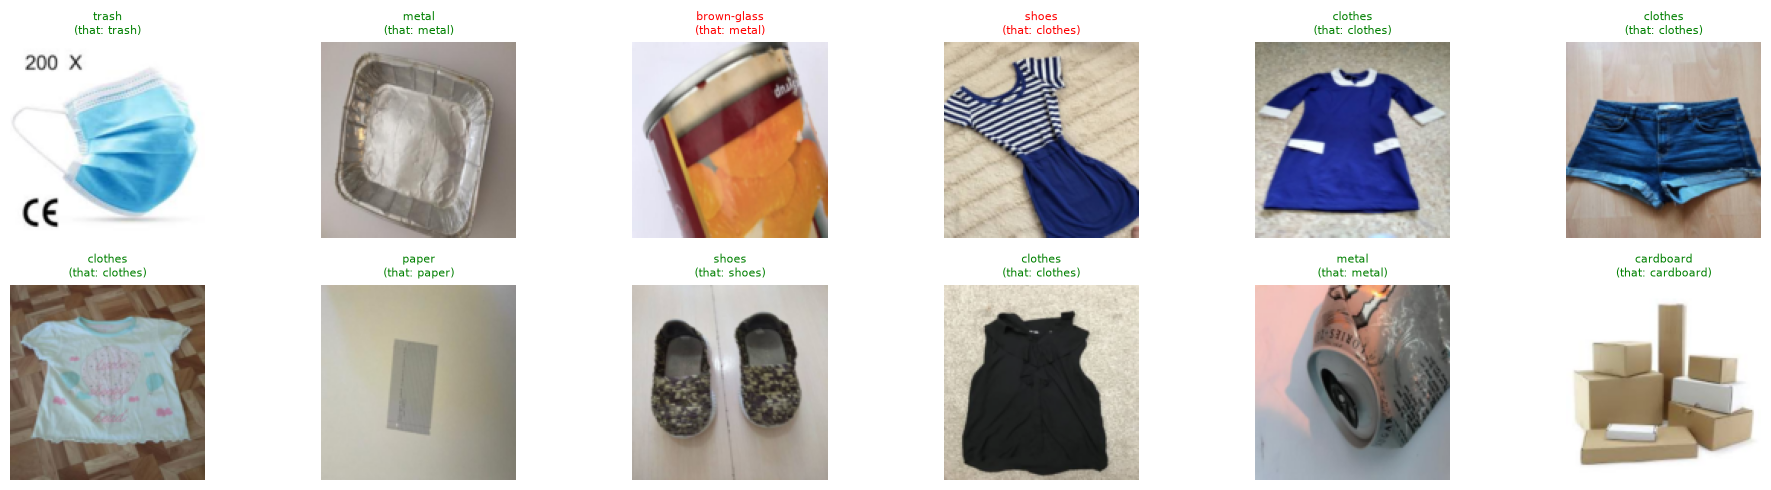

In [9]:
C.show_predictions(model, loaders['test'], classes)

## 5. Nhận xét

**Kết quả:** ResNet18 đạt **94,0% accuracy** và **macro F1 = 0,923** trên tập test (11,2 triệu tham số, train 10 epoch, khoảng 7,8 phút). Cao hơn CNN tự xây khoảng **10,9 điểm phần trăm** accuracy với ít epoch hơn một nửa.

**Quá trình huấn luyện:** val accuracy cao nhất là 95,2%, trong khi train accuracy cuối là 98,9%. Chênh lệch khoảng 3,7 điểm giữa train và val cho thấy mô hình có **overfit nhẹ**, nhưng vẫn chấp nhận được. Trọng số pretrained từ ImageNet giúp mạng hội tụ nhanh ngay từ vài epoch đầu.

**Theo từng lớp (F1):** tốt nhất là `clothes` (0,981), `trash` (0,951), `green-glass` (0,947), `brown-glass` (0,946). Yếu nhất là `plastic` (0,846), `metal` (0,881) và `white-glass` (0,889).

**Lỗi hay gặp:** `clothes` đoán thành `shoes` (17 ảnh), `plastic` đoán thành `white-glass` (8 ảnh), `cardboard` đoán thành `paper` (7 ảnh). Các cặp này thật sự giống nhau về hình thức (nhựa trong và thủy tinh trong; bìa carton và giấy).

**Kết luận:** transfer learning giúp tăng mạnh kết quả so với train từ đầu. Skip connection của ResNet làm việc train ổn định. Tuy nhiên ResNet18 có nhiều tham số hơn EfficientNet-B0 gấp khoảng 2,8 lần nhưng kết quả lại thấp hơn.